# Methanol LCA

## Setup

### Imports

In [1]:
# False: rebuild the alternative (foreground) inventories from inventories.xlsx, replacing
#        the databases already in Brightway. Use it after editing the Excel.
# True:  reuse the foreground databases already in Brightway (cached).
USE_CACHED_FOREGROUND = False

import os
import logging

from dotenv import load_dotenv
load_dotenv()
os.makedirs(os.environ["BRIGHTWAY2_DIR"], exist_ok=True)


import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import bw2calc as bc
import bw2data as bd
import bw2io as bi
from regioinvent import Regioinvent
from constructive_geometries import Geomatcher

from rapidfuzz import fuzz, process
from tqdm.auto import tqdm

Using environment variable BRIGHTWAY2_DIR for data directory:
D:\Brightway
2026-10-21T12:26:23.884383Z [warning  ] Brightway not installed; Brightway IO functionality disabled [wurst]


### Configuration

In [2]:
PROJECT           = "Methanol_LCA"
ECOINVENT_VERSION = "3.10"
ECOINVENT_DB_NAME = "ecoinvent-3.10-cutoff"
BIOSPHERE_DB_NAME = "ecoinvent-3.10-biosphere"

TRADE_DB_PATH = os.environ.get("TRADE_DATABASE_PATH")

REGIOINVENT_DB_NAME       = f"{ECOINVENT_DB_NAME}-regioinvent"
REGIOINVENT_CUTOFF        = 0.99
UPSTREAM_TRAVERSAL_DEPTH  = 3  # technosphere hops walked upstream to find traded products to regionalize

SPATIALIZED_ECOINVENT_DB_NAME = f"{ECOINVENT_DB_NAME} - regionalized"
SPATIALIZED_BIOSPHERE_DB_NAME = "biosphere3_spatialized_flows"

FOREGROUND_DB_NAME      = "alternative-inventories-ei310"
FOREGROUND_DB_LOC_NAME  = f"{FOREGROUND_DB_NAME}-regionalized"
INVENTORY_XLSX_PATH     = "inventories.xlsx"
# All generated tables, logs and figures are saved in this folder (created if missing)
from pathlib import Path
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_LOG_XLSX        = RESULTS_DIR / "mapping_log_foreground.xlsx"

# Foreground localization: background candidates are gathered by (reference product,
# unit, location) and disambiguated by rapidfuzz string similarity (0-100 scale)
# between the original exchange's name and each candidate's name.
FUZZY_SIMILARITY_THRESHOLD = 75

GLO_ACTIVITY_NAMES = [
    "methanol production, CO2 hydrogenation",
    "hydrogen production, PEM electrolysis",
    "carbon dioxide capture, point-source emission",
]
METHANOL_ACTIVITY_NAME = "methanol production, CO2 hydrogenation"

LCA_RESULTS_XLSX    = RESULTS_DIR / "lca_results_glo.xlsx"                # GLO (unlocalized) scores, all routes
LCA_RESULTS_REGIONALIZED_XLSX = RESULTS_DIR / "lca_results_regionalized.xlsx"  # scores by country, all routes
METHANOL_GWP_MAP_PNG = RESULTS_DIR / "methanol_gwp_map.png"
NATURAL_EARTH_URL    = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"

GWP_METHOD = (
    "IPCC 2021",
    "climate change",
    "global warming potential (GWP100)",
)

## Ecoinvent

In [3]:
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logging.getLogger("bw2calc").setLevel(logging.WARNING)

bd.projects.set_current(PROJECT)

if ECOINVENT_DB_NAME not in bd.databases:
    logging.info(f"Importing {ECOINVENT_DB_NAME} (one-time)...")
    bi.import_ecoinvent_release(
        version=ECOINVENT_VERSION,
        system_model="cutoff",
        username=os.environ.get("ECOINVENT_USERNAME"),
        password=os.environ.get("ECOINVENT_PASSWORD"),
    )

## Foreground Inventory (GLO)

In [4]:
if not USE_CACHED_FOREGROUND:
    # Drop the previous foreground (and its localized copy) so they are rebuilt from the Excel
    for stale_db in (FOREGROUND_DB_LOC_NAME, FOREGROUND_DB_NAME):
        if stale_db in bd.databases:
            logging.info(f"USE_CACHED_FOREGROUND is False: deleting {stale_db!r}.")
            del bd.databases[stale_db]

if FOREGROUND_DB_NAME not in bd.databases or len(bd.Database(FOREGROUND_DB_NAME)) == 0:
    logging.info(f"Importing foreground inventory into {FOREGROUND_DB_NAME} (direct to {ECOINVENT_DB_NAME})...")
    foreground_direct = bi.ExcelImporter(INVENTORY_XLSX_PATH)
    foreground_direct.apply_strategies()

    foreground_direct.match_database(ECOINVENT_DB_NAME, fields=("name", "reference product", "unit", "location"))
    foreground_direct.match_database(BIOSPHERE_DB_NAME, fields=("name", "unit", "categories"))
    foreground_direct.statistics()

    unlinked = [exc for ds in foreground_direct.data for exc in ds.get("exchanges", []) if "input" not in exc]
    if unlinked:
        for exc in unlinked:
            logging.error(
                f"Unlinked {exc.get('type')}: name={exc.get('name')!r} "
                f"location={exc.get('location')!r} database={exc.get('database')!r}"
            )
        raise RuntimeError(f"{len(unlinked)} exchange(s) failed to link; fix inventories.xlsx and re-run.")

    foreground_direct.write_database()
else:
    logging.info(f"{FOREGROUND_DB_NAME!r} already exists, skipping foreground import.")

INFO: USE_CACHED_FOREGROUND is False: deleting 'alternative-inventories-ei310-regionalized'.


Vacuuming database 


INFO: USE_CACHED_FOREGROUND is False: deleting 'alternative-inventories-ei310'.
INFO: Importing foreground inventory into alternative-inventories-ei310 (direct to ecoinvent-3.10-cutoff)...


Extracted 1 worksheets in 0.01 seconds
Applying strategy: csv_restore_tuples
Applying strategy: csv_restore_booleans
Applying strategy: csv_numerize
Applying strategy: csv_drop_unknown
Applying strategy: csv_add_missing_exchanges_section
Applying strategy: normalize_units
Applying strategy: normalize_biosphere_categories
Applying strategy: normalize_biosphere_names
Applying strategy: strip_biosphere_exc_locations
Applying strategy: set_code_by_activity_hash
Applying strategy: link_iterable_by_fields
Applying strategy: assign_only_product_as_production
Applying strategy: link_technosphere_by_activity_hash
Applying strategy: drop_falsey_uncertainty_fields_but_keep_zeros
Applying strategy: convert_uncertainty_types_to_integers
Applying strategy: convert_activity_parameters_to_list
Applied 16 strategies in 2.72 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields
3 datasets
19 exchanges
0 unlinked exchanges
  


Writing activities to SQLite3 database:
0% [###] 100% | ETA: 00:00:00
Total time elapsed: 00:00:00


Title: Writing activities to SQLite3 database:
  Started: 10/21/2026 14:28:47
  Finished: 10/21/2026 14:28:47
  Total time elapsed: 00:00:00
  CPU %: 0.00
  Memory %: 0.48
Created database: alternative-inventories-ei310


In [5]:
def get_activity_by_name(db_name, name):
    candidates = [a for a in bd.Database(db_name) if a.get("name") == name]
    if len(candidates) != 1:
        raise KeyError(f"Expected exactly one activity named {name!r} in {db_name!r}, found {len(candidates)}")
    return candidates[0]


glo_lca_scores = {}
for name in GLO_ACTIVITY_NAMES:
    act = get_activity_by_name(FOREGROUND_DB_NAME, name)
    lca = bc.LCA({act: 1}, GWP_METHOD)
    lca.lci()
    lca.lcia()
    glo_lca_scores[name] = lca.score
    logging.info(f"{name}: {lca.score:.4g} kg CO2-eq per {act.get('unit')}")

pd.Series(glo_lca_scores, name="GWP100_kgCO2eq").to_excel(LCA_RESULTS_XLSX)
logging.info(f"LCA results saved: {LCA_RESULTS_XLSX}")

INFO: methanol production, CO2 hydrogenation: 3.134 kg CO2-eq per kilogram
INFO: hydrogen production, PEM electrolysis: 1.361 kg CO2-eq per kilogram
INFO: carbon dioxide capture, point-source emission: 0.471 kg CO2-eq per kilogram
INFO: LCA results saved: results\lca_results_glo.xlsx


## Regionalization

In [6]:
def traded_products_upstream(root_activities, ecoinvent_db_name, max_depth, max_nodes=5000):
    """BFS over technosphere exchanges starting at root_activities, following both
    foreground-internal and ecoinvent branches up to max_depth hops. Returns the
    reference products of every ecoinvent_db_name activity reached. No magnitude
    cutoff -- every technosphere edge counts, so max_depth controls the size; it
    grows fast, so raise it cautiously.
    """
    visited_products = set()
    seen = set()
    frontier = [(act, 0) for act in root_activities]
    while frontier:
        if len(seen) >= max_nodes:
            logging.warning(
                f"traded_products_upstream: hit max_nodes={max_nodes}, stopping early; "
                f"consider lowering UPSTREAM_TRAVERSAL_DEPTH."
            )
            break
        act, depth = frontier.pop()
        if act.key in seen or depth > max_depth:
            continue
        seen.add(act.key)
        for exc in act.exchanges():
            if exc["type"] != "technosphere":
                continue
            child = bd.get_activity(exc.input)
            if child["database"] == ecoinvent_db_name:
                visited_products.add(child.get("reference product"))
            frontier.append((child, depth + 1))
    logging.info(f"Upstream traversal visited {len(seen)} activities (max_depth={max_depth}).")
    return visited_products


if REGIOINVENT_DB_NAME not in bd.databases:
    logging.info(f"Regionalizing {ECOINVENT_DB_NAME} with trade data (one-time)...")
    ri = Regioinvent(
        bw_project_name=PROJECT,
        ecoinvent_database_name=ECOINVENT_DB_NAME,
        ecoinvent_version=ECOINVENT_VERSION,
    )
    ri.spatialize_my_ecoinvent()
    ri.import_fully_regionalized_impact_method(lcia_method="all")

    # Traded products relevant to this supply chain: walk the technosphere graph of our
    # own foreground activities (methanol, hydrogen, CO2 capture) up to
    # UPSTREAM_TRAVERSAL_DEPTH hops, not just their direct inputs, so upstream traded
    # commodities (e.g. natural gas feeding steam production) get picked up too.
    root_activities = [get_activity_by_name(FOREGROUND_DB_NAME, name) for name in GLO_ACTIVITY_NAMES]
    upstream_products = traded_products_upstream(root_activities, ECOINVENT_DB_NAME, UPSTREAM_TRAVERSAL_DEPTH)
    relevant_traded_products = upstream_products & set(ri.eco_to_hs_class)
    logging.info(f"Internationally-traded products found upstream: {sorted(relevant_traded_products)}")

    before = len(ri.eco_to_hs_class)
    ri.eco_to_hs_class = {k: v for k, v in ri.eco_to_hs_class.items() if k in relevant_traded_products}
    logging.info(f"Restricted traded products for regionalization: {before} -> {len(ri.eco_to_hs_class)}")

    ri.regionalize_ecoinvent_with_trade(
        trade_database_path=TRADE_DB_PATH,
        target_database_name=REGIOINVENT_DB_NAME,
        cutoff=REGIOINVENT_CUTOFF,
    )
else:
    logging.info(f"{REGIOINVENT_DB_NAME!r} already exists, skipping regionalization.")

INFO: 'ecoinvent-3.10-cutoff-regioinvent' already exists, skipping regionalization.


## Foreground Regionalization

In [7]:
world = gpd.read_file(NATURAL_EARTH_URL)
# ISO_A2 has a known bug (France/Norway show "-99"); ISO_A2_EH is the corrected version.
VALID_COUNTRY_CODES = set(world["ISO_A2_EH"]) - {"-99"}


def extract_target_locations_from_db(db_name, valid_locations, exclude=("GLO", "RoW")):
    """Only keep locations that are real, mappable ISO country codes -- drops GLO/RoW
    plus ecoinvent's own regional aggregates (RER, RAS, RNA, ...), which aren't
    countries and would just be silently dropped by the map merge anyway."""
    db = bd.Database(db_name)
    locations = {a.get("location") for a in db if a.get("location") not in set(exclude)}
    locations.discard(None)
    return sorted(locations & valid_locations)


def region_fallback_chain(geomatcher, country_code, _cache={}):
    """Ecoinvent-style regions containing country_code, narrowest first (e.g.
    DE -> RER -> ... -> GLO), used as a fallback when no country-specific
    candidate exists for a technosphere input."""
    if country_code in _cache:
        return _cache[country_code]
    try:
        contained_in = geomatcher.within(country_code, biggest_first=False)
    except KeyError:
        contained_in = []
    chain = [entry[1] if isinstance(entry, tuple) else entry for entry in contained_in]
    chain = [loc for loc in chain if loc != country_code]
    _cache[country_code] = chain
    return chain


def build_candidate_index(background_db_names):
    """Candidates grouped by (reference product, unit, location) -- not by name, so
    multiple technology variants of the same product at a location are all considered."""
    index = {}
    for name in background_db_names:
        for act in bd.Database(name):
            key = (act.get("reference product"), act.get("unit"), act.get("location"))
            index.setdefault(key, []).append(act)
    return index


def exchange_dict_with_input(exc, new_input):
    data = exc.as_dict()
    data["input"] = new_input
    return data


def best_fuzzy_match(reference_name, candidate_names, _cache={}):
    if not candidate_names:
        return None, None
    cache_key = (reference_name, tuple(candidate_names))
    if cache_key in _cache:
        return _cache[cache_key]
    best_name, score, _ = process.extractOne(reference_name, candidate_names, scorer=fuzz.token_sort_ratio)
    result = (best_name, score)
    _cache[cache_key] = result
    return result


def best_candidate_with_fallback(candidate_index, geomatcher, reference_product, unit, loc, reference_name, similarity_threshold):
    """Try loc first, then progressively broader ecoinvent regions containing loc
    (e.g. DE -> RER -> GLO), returning the first adequate fuzzy match found."""
    for candidate_location in [loc] + region_fallback_chain(geomatcher, loc):
        candidates = candidate_index.get((reference_product, unit, candidate_location), [])
        if not candidates:
            continue
        candidate_names = [c.get("name") for c in candidates]
        best_name, score = best_fuzzy_match(reference_name, candidate_names)
        if best_name is not None and score >= similarity_threshold:
            matched = next(c for c in candidates if c.get("name") == best_name)
            return matched, best_name, score, candidate_location
    return None, None, None, None


def localize_foreground_database(
    original_fg_db_name,
    output_fg_db_name,
    background_db_names,
    target_locations,
    similarity_threshold,
    geomatcher,
    mapping_log_xlsx,
    source_activities=None,
):
    """Clone activities into many locations, localizing technosphere exchanges.

    The activities to clone are all of original_fg_db_name, or just
    source_activities if given (e.g. a few ecoinvent activities, so no
    intermediate copy database is needed).

    Rules (in order): production exchanges are copied as-is (self-production
    points at the localized activity); same-DB (foreground-internal) exchanges
    redirect to the localized sibling; exchanges already at the target location
    are kept; otherwise candidates sharing (reference product, unit, location)
    are searched for at the target location and then, if none match well enough,
    at progressively broader ecoinvent regions containing it (e.g. DE -> RER ->
    GLO), ranked by rapidfuzz string similarity of their name against the
    original exchange's name; the best one is used if its score clears
    similarity_threshold; else the original exchange is kept unchanged.
    """
    if output_fg_db_name in bd.databases:
        del bd.databases[output_fg_db_name]

    source_activities = list(source_activities) if source_activities is not None else list(bd.Database(original_fg_db_name))
    candidate_index = build_candidate_index(background_db_names)

    expected_localized_keys = {
        (output_fg_db_name, act.key[1] + f"_{loc}")
        for act in source_activities
        for loc in target_locations
    }

    log_entries = []
    new_db_data = {}

    for loc in tqdm(target_locations, desc=f"Localizing '{original_fg_db_name}' (fuzzy matching)"):
        for act in source_activities:
            localized_key = (output_fg_db_name, act.key[1] + f"_{loc}")
            new_act_data = {
                "name": act["name"],
                "reference product": act.get("reference product"),
                "unit": act.get("unit"),
                "location": loc,
                "classifications": list(act.get("classifications") or []),
                "exchanges": [],
            }

            for exc in act.exchanges():
                if exc["type"] == "production":
                    if exc.input.key == act.key:
                        new_act_data["exchanges"].append(exchange_dict_with_input(exc, localized_key))
                    else:
                        new_act_data["exchanges"].append(exc.as_dict())
                    continue
                if exc["type"] != "technosphere":
                    new_act_data["exchanges"].append(exc.as_dict())
                    continue

                input_act = bd.get_activity(exc.input)

                if input_act.key[0] == original_fg_db_name:
                    localized_fg_key = (output_fg_db_name, input_act.key[1] + f"_{loc}")
                    if localized_fg_key in expected_localized_keys:
                        new_act_data["exchanges"].append(exchange_dict_with_input(exc, localized_fg_key))
                        log_entries.append({"target_location": loc, "activity": act.get("name"), "product": input_act.get("name"),
                            "original_location": input_act.get("location"), "new_location": loc,
                            "matched_name": input_act.get("name"), "similarity": 100.0, "status": "redirected (FG-first)"})
                        continue

                if input_act.get("location") == loc:
                    new_act_data["exchanges"].append(exc.as_dict())
                    log_entries.append({"target_location": loc, "activity": act.get("name"), "product": input_act.get("name"),
                        "original_location": input_act.get("location"), "new_location": loc,
                        "matched_name": input_act.get("name"), "similarity": 100.0, "status": "unchanged (already localized)"})
                    continue

                matched, best_name, score, matched_location = best_candidate_with_fallback(
                    candidate_index, geomatcher,
                    input_act.get("reference product"), input_act.get("unit"), loc,
                    input_act.get("name"), similarity_threshold,
                )

                if matched is None:
                    new_act_data["exchanges"].append(exc.as_dict())
                    log_entries.append({"target_location": loc, "activity": act.get("name"), "product": input_act.get("name"),
                        "original_location": input_act.get("location"), "new_location": input_act.get("location"),
                        "matched_name": None, "similarity": None, "status": "unchanged (no adequate match at any tier)"})
                    continue

                new_act_data["exchanges"].append(exchange_dict_with_input(exc, matched.key))
                status = "changed (fuzzy match)" if matched_location == loc else f"changed (regional fallback: {matched_location})"
                log_entries.append({"target_location": loc, "activity": act.get("name"), "product": input_act.get("name"),
                    "original_location": input_act.get("location"), "new_location": matched.get("location"),
                    "matched_name": best_name, "similarity": round(score, 1), "status": status})

            new_db_data[localized_key] = new_act_data

    bd.Database(output_fg_db_name).write(new_db_data)
    bd.Database(output_fg_db_name).process()
    logging.info(f"Localized DB written: {output_fg_db_name} ({len(new_db_data)} activities)")

    pd.DataFrame(log_entries).to_excel(mapping_log_xlsx, index=False)
    logging.info(f"Mapping log saved: {mapping_log_xlsx}")


if not USE_CACHED_FOREGROUND or FOREGROUND_DB_LOC_NAME not in bd.databases or len(bd.Database(FOREGROUND_DB_LOC_NAME)) == 0:
    logging.info(f"Regionalizing {FOREGROUND_DB_NAME} across regioinvent locations...")
    target_locations = extract_target_locations_from_db(REGIOINVENT_DB_NAME, VALID_COUNTRY_CODES)
    logging.info(f"Target locations: {len(target_locations)}")

    localize_foreground_database(
        original_fg_db_name=FOREGROUND_DB_NAME,
        output_fg_db_name=FOREGROUND_DB_LOC_NAME,
        background_db_names=[SPATIALIZED_ECOINVENT_DB_NAME, REGIOINVENT_DB_NAME],
        target_locations=target_locations,
        similarity_threshold=FUZZY_SIMILARITY_THRESHOLD,
        geomatcher=Geomatcher(),
        mapping_log_xlsx=MAPPING_LOG_XLSX,
    )
else:
    logging.info(f"{FOREGROUND_DB_LOC_NAME!r} already exists, skipping foreground regionalization.")

INFO: Regionalizing alternative-inventories-ei310 across regioinvent locations...
INFO: Target locations: 169


Localizing 'alternative-inventories-ei310' (fuzzy matching):   0%|          | 0/169 [00:00<?, ?it/s]

Writing activities to SQLite3 database:
0% [##############################] 100% | ETA: 00:00:00
Total time elapsed: 00:00:00


Title: Writing activities to SQLite3 database:
  Started: 10/21/2026 14:28:55
  Finished: 10/21/2026 14:28:55
  Total time elapsed: 00:00:00
  CPU %: 69.70
  Memory %: 1.24


INFO: Localized DB written: alternative-inventories-ei310-regionalized (507 activities)
INFO: Mapping log saved: results\mapping_log_foreground.xlsx


## GWP Calculations by Country

### CO2 Hydrogenation

In [8]:
methanol_by_location = {
    a.get("location"): a
    for a in bd.Database(FOREGROUND_DB_LOC_NAME)
    if a.get("name") == METHANOL_ACTIVITY_NAME
}
locations_sorted = sorted(methanol_by_location)
logging.info(f"Computing GWP for {METHANOL_ACTIVITY_NAME!r} across {len(locations_sorted)} locations...")

first_loc = locations_sorted[0]
lca = bc.LCA({methanol_by_location[first_loc]: 1}, GWP_METHOD)
lca.lci(factorize=True)
lca.lcia()

# the first location is already computed above, so the bar starts at 1 and ends at len(locations_sorted)
methanol_gwp_by_location = {first_loc: lca.score}
with tqdm(total=len(locations_sorted), initial=1, desc="CO2 hydrogenation") as bar:
    for loc in locations_sorted[1:]:
        lca.redo_lcia({methanol_by_location[loc]: 1})
        methanol_gwp_by_location[loc] = lca.score
        bar.update(1)

methanol_gwp_df = (
    pd.Series(methanol_gwp_by_location, name="GWP100_kgCO2eq_per_kg")
    .rename_axis("location")
    .reset_index()
)

methanol_gwp_df.describe()

INFO: Computing GWP for 'methanol production, CO2 hydrogenation' across 169 locations...


CO2 hydrogenation:   1%|          | 1/169 [00:00<?, ?it/s]

,GWP100_kgCO2eq_per_kg
count,169.000000
mean,2.670458
std,0.546360
min,1.406531
25%,2.265810
50%,2.790926
75%,3.100252
max,3.764302


### Conventional Routes (natural gas reforming, coal gasification, market)

In [9]:
CONVENTIONAL_DB_LOC_NAME      = "methanol-conventional-regionalized"  # one DB for all conventional routes
CONVENTIONAL_MAPPING_LOG_XLSX = RESULTS_DIR / "mapping_log_conventional.xlsx"

# ecoinvent source activities (RoW = rest-of-world proxy, since country-level
# datasets only exist for CN/RER/US). Localized straight from ecoinvent -- no
# intermediate copy database.
CONVENTIONAL_ROUTES = {
    "natural_gas_reforming": "methanol production, natural gas reforming",
    "coal_gasification":     "methanol production, coal gasification",
    "market":                "market for methanol",
}
CONVENTIONAL_SOURCE_LOCATION = "RoW"

conventional_sources = {
    route: next(
        a for a in bd.Database(ECOINVENT_DB_NAME)
        if a.get("name") == act_name
        and a.get("reference product") == "methanol"
        and a.get("location") == CONVENTIONAL_SOURCE_LOCATION
    )
    for route, act_name in CONVENTIONAL_ROUTES.items()
}

if CONVENTIONAL_DB_LOC_NAME not in bd.databases or len(bd.Database(CONVENTIONAL_DB_LOC_NAME)) == 0:
    localize_foreground_database(
        original_fg_db_name=ECOINVENT_DB_NAME,
        output_fg_db_name=CONVENTIONAL_DB_LOC_NAME,
        background_db_names=[SPATIALIZED_ECOINVENT_DB_NAME, REGIOINVENT_DB_NAME],
        target_locations=extract_target_locations_from_db(REGIOINVENT_DB_NAME, VALID_COUNTRY_CODES),
        similarity_threshold=FUZZY_SIMILARITY_THRESHOLD,
        geomatcher=Geomatcher(),
        mapping_log_xlsx=CONVENTIONAL_MAPPING_LOG_XLSX,
        source_activities=conventional_sources.values(),
    )

conventional_gwp = {}
for route, src in conventional_sources.items():
    by_location = {
        a.get("location"): a
        for a in bd.Database(CONVENTIONAL_DB_LOC_NAME)
        if a.get("name") == src["name"]
    }
    locs = sorted(by_location)
    logging.info(f"Computing GWP for {src['name']!r} across {len(locs)} locations...")

    lca = bc.LCA({by_location[locs[0]]: 1}, GWP_METHOD)
    lca.lci(factorize=True)
    lca.lcia()
    scores = {locs[0]: lca.score}
    # the first location is already computed above, so the bar starts at 1 and ends at len(locs)
    with tqdm(total=len(locs), initial=1, desc=route) as bar:
        for loc in locs[1:]:
            lca.redo_lcia({by_location[loc]: 1})
            scores[loc] = lca.score
            bar.update(1)
    conventional_gwp[route] = scores

conventional_gwp_df = pd.DataFrame(conventional_gwp).rename_axis("location").reset_index()

# GLO (unlocalized) scores of the conventional routes, added to the GLO table.
# These are the ecoinvent source activities (see CONVENTIONAL_SOURCE_LOCATION).
for route, src in conventional_sources.items():
    lca_src = bc.LCA({src: 1}, GWP_METHOD)
    lca_src.lci()
    lca_src.lcia()
    glo_lca_scores[f"{src['name']} [{src['location']}]"] = lca_src.score
pd.Series(glo_lca_scores, name="GWP100_kgCO2eq").to_excel(LCA_RESULTS_XLSX)
logging.info(f"LCA results saved: {LCA_RESULTS_XLSX}")

# Regionalized table: every route by country in a single Excel
regionalized_df = methanol_gwp_df.rename(columns={"GWP100_kgCO2eq_per_kg": "co2_hydrogenation"}).merge(
    conventional_gwp_df, on="location", how="outer"
)
# country name next to the ISO code (Natural Earth names, loaded in the foreground regionalization section)
# "-99" is the placeholder code of unrecognised territories (Somaliland, N. Cyprus) and appears twice, so drop it
country_names = world[world["ISO_A2_EH"] != "-99"].set_index("ISO_A2_EH")["NAME_EN"]
regionalized_df.insert(1, "country", regionalized_df["location"].map(country_names))
regionalized_df.to_excel(LCA_RESULTS_REGIONALIZED_XLSX, index=False)
logging.info(f"Saved {LCA_RESULTS_REGIONALIZED_XLSX} ({len(regionalized_df)} locations)")

conventional_gwp_df.describe()

INFO: Computing GWP for 'methanol production, natural gas reforming' across 169 locations...


natural_gas_reforming:   1%|          | 1/169 [00:00<?, ?it/s]

INFO: Computing GWP for 'methanol production, coal gasification' across 169 locations...


coal_gasification:   1%|          | 1/169 [00:00<?, ?it/s]

INFO: Computing GWP for 'market for methanol' across 169 locations...


market:   1%|          | 1/169 [00:00<?, ?it/s]

INFO: LCA results saved: results\lca_results_glo.xlsx
INFO: Saved results\lca_results_regionalized.xlsx (169 locations)


,natural_gas_reforming,coal_gasification,market
count,169.000000,169.000000,169.000000
mean,0.851662,3.785373,0.918004
std,0.076497,0.489753,0.076771
min,0.673072,2.614797,0.737976
25%,0.814739,3.494773,0.882234
50%,0.855273,3.655146,0.922248
75%,0.895104,4.057281,0.959109
max,1.260245,5.436191,1.319638


## Maps

### CO2 Hydrogenation

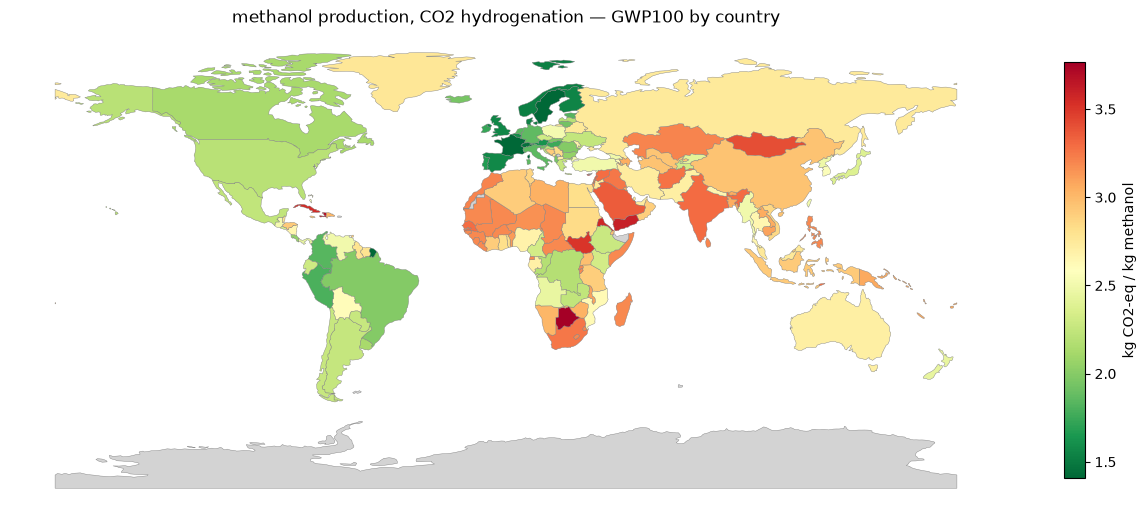

INFO: Map saved: results\methanol_gwp_map.png


In [10]:
merged = world.merge(methanol_gwp_df, left_on="ISO_A2_EH", right_on="location", how="left")

fig, ax = plt.subplots(figsize=(16, 9))
merged.plot(
    column="GWP100_kgCO2eq_per_kg",
    cmap="RdYlGn_r",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "kg CO2-eq / kg methanol", "shrink": 0.6},
    missing_kwds={"color": "lightgrey", "label": "no data"},
    ax=ax,
)
ax.set_title(f"{METHANOL_ACTIVITY_NAME} — GWP100 by country")
ax.axis("off")
plt.savefig(METHANOL_GWP_MAP_PNG, dpi=200, bbox_inches="tight")
plt.show()
logging.info(f"Map saved: {METHANOL_GWP_MAP_PNG}")

### Natural Gas Reforming

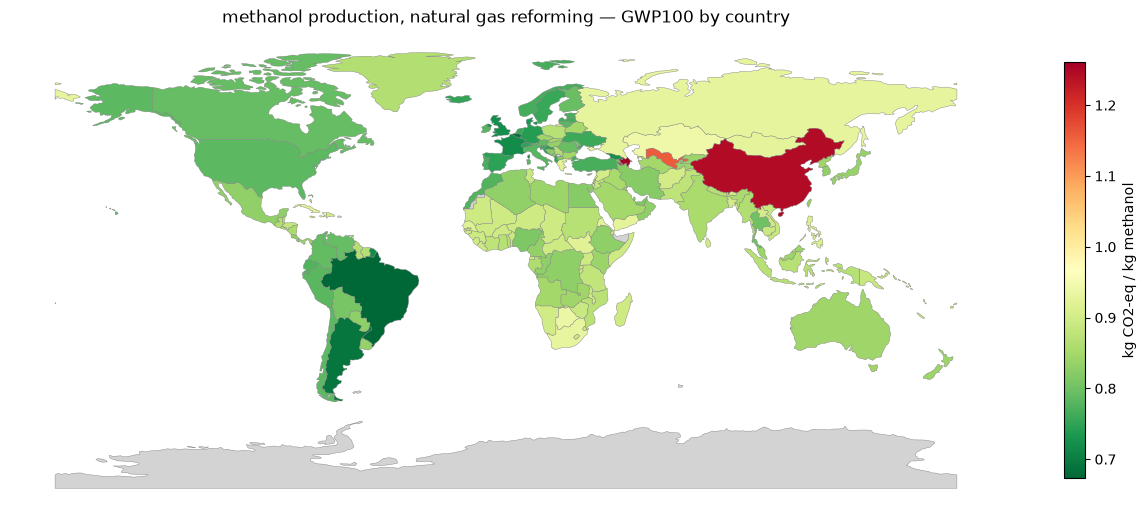

INFO: Map saved: results\methanol_natural_gas_reforming_gwp_map.png


In [11]:
merged_ngr = world.merge(conventional_gwp_df[["location", "natural_gas_reforming"]], left_on="ISO_A2_EH", right_on="location", how="left")

fig, ax = plt.subplots(figsize=(16, 9))
merged_ngr.plot(
    column="natural_gas_reforming",
    cmap="RdYlGn_r",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "kg CO2-eq / kg methanol", "shrink": 0.6},
    missing_kwds={"color": "lightgrey", "label": "no data"},
    ax=ax,
)
ax.set_title(f"{CONVENTIONAL_ROUTES['natural_gas_reforming']} — GWP100 by country")
ax.axis("off")
plt.savefig(RESULTS_DIR / "methanol_natural_gas_reforming_gwp_map.png", dpi=200, bbox_inches="tight")
plt.show()
logging.info(f"Map saved: {RESULTS_DIR / 'methanol_natural_gas_reforming_gwp_map.png'}")

### Coal Gasification

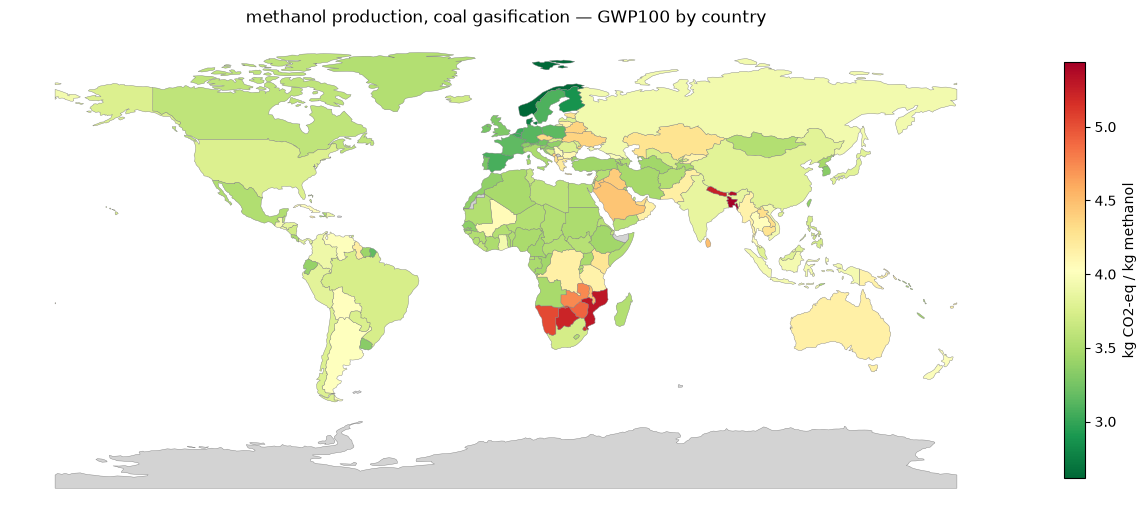

INFO: Map saved: results\methanol_coal_gasification_gwp_map.png


In [12]:
merged_coal = world.merge(conventional_gwp_df[["location", "coal_gasification"]], left_on="ISO_A2_EH", right_on="location", how="left")

fig, ax = plt.subplots(figsize=(16, 9))
merged_coal.plot(
    column="coal_gasification",
    cmap="RdYlGn_r",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "kg CO2-eq / kg methanol", "shrink": 0.6},
    missing_kwds={"color": "lightgrey", "label": "no data"},
    ax=ax,
)
ax.set_title(f"{CONVENTIONAL_ROUTES['coal_gasification']} — GWP100 by country")
ax.axis("off")
plt.savefig(RESULTS_DIR / "methanol_coal_gasification_gwp_map.png", dpi=200, bbox_inches="tight")
plt.show()
logging.info(f"Map saved: {RESULTS_DIR / 'methanol_coal_gasification_gwp_map.png'}")

### Market for Methanol

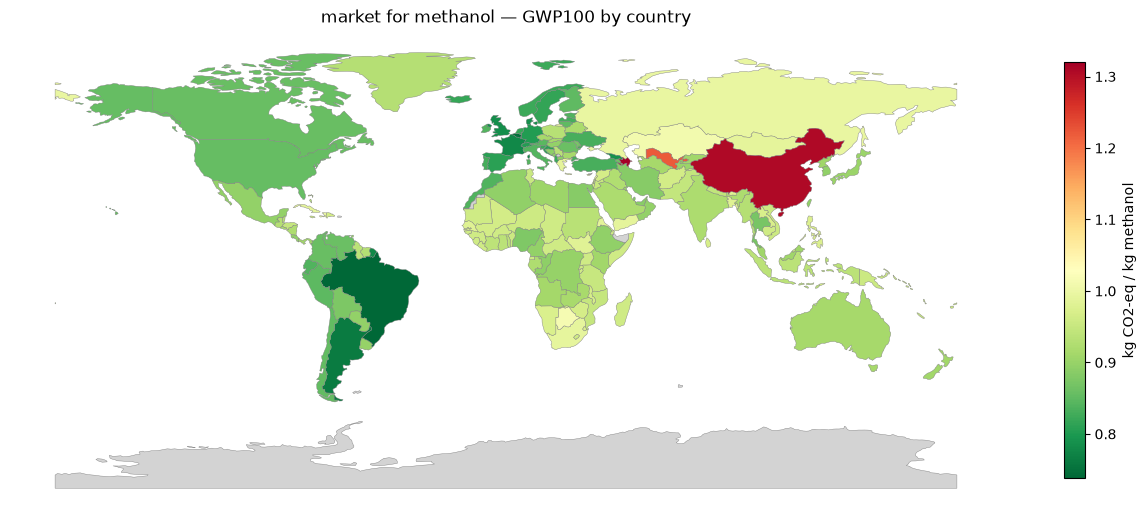

INFO: Map saved: results\methanol_market_gwp_map.png


In [13]:
merged_market = world.merge(conventional_gwp_df[["location", "market"]], left_on="ISO_A2_EH", right_on="location", how="left")

fig, ax = plt.subplots(figsize=(16, 9))
merged_market.plot(
    column="market",
    cmap="RdYlGn_r",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "kg CO2-eq / kg methanol", "shrink": 0.6},
    missing_kwds={"color": "lightgrey", "label": "no data"},
    ax=ax,
)
ax.set_title(f"{CONVENTIONAL_ROUTES['market']} — GWP100 by country")
ax.axis("off")
plt.savefig(RESULTS_DIR / "methanol_market_gwp_map.png", dpi=200, bbox_inches="tight")
plt.show()
logging.info(f"Map saved: {RESULTS_DIR / 'methanol_market_gwp_map.png'}")